# Limit order book & imbalance modeling with `quantstats.lob`

This notebook records a few minutes of live 10-level order book snapshots from
Binance's public market-data API (no key needed) and runs every model in
`quantstats.lob` on them:

1. book features and the order book ladder,
2. **queue imbalance** as a predictor of the next price move,
3. **order flow imbalance (OFI)** and linear price impact,
4. Stoikov's **micro-price**, fitted on the first half and tested on the second.

If Binance can't be reached from where you run this, it falls back to a
simulated book so every cell still runs.

Large-tick instruments (spread usually one tick, deep queues) are where
imbalance models shine, so the default symbol is `DOGEUSDT`. Try `BTCUSDT` to
see a small-tick market where the micro-price adds nothing.

In [1]:
import logging
import time

import numpy as np
import pandas as pd
import requests

import quantstats as qs
from quantstats import lob

SYMBOL = "DOGEUSDT"
SECONDS = 300      # how long to record
LEVELS = 10

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

## 1. Record order book snapshots

`lob.from_depth` turns exchange depth snapshots (`{"bids": [[price, size], ...], "asks": [...]}`)
into the book layout every `lob` function takes: one row per snapshot with
`bid_price_1`, `bid_size_1`, `ask_price_1`, `ask_size_1`, ... columns.

In [2]:
URL = "https://data-api.binance.vision/api/v3/depth"


def record(symbol, seconds, levels=10, interval=0.2):
    """Poll REST depth snapshots, keeping each new book once."""
    session, snaps, stamps, last = requests.Session(), [], [], None
    end = time.time() + seconds
    while time.time() < end:
        t0 = time.time()
        d = session.get(URL, params={"symbol": symbol, "limit": levels}, timeout=5).json()
        if d["lastUpdateId"] != last:
            last = d["lastUpdateId"]
            snaps.append(d)
            stamps.append(pd.Timestamp(t0, unit="s"))
        time.sleep(max(0.0, interval - (time.time() - t0)))
    return lob.from_depth(snaps, timestamps=stamps)


def simulate(n=6000, tick=0.01, seed=7):
    """Fallback: a symmetric book where the thinner queue tends to empty first."""
    rng = np.random.default_rng(seed)
    bid, ask, qb, qa, rows = 10000, 10001, 50.0, 50.0, []
    for _ in range(n):
        qb += rng.normal(0, 8); qa += rng.normal(0, 8); wide = ask - bid > 1
        if qa <= 0:
            ask += 1; bid += wide; qa = rng.uniform(20, 80); qb = rng.uniform(5, 30) if wide else qb
        elif qb <= 0:
            bid -= 1; ask -= wide; qb = rng.uniform(20, 80); qa = rng.uniform(5, 30) if wide else qa
        elif wide and rng.random() < 0.5:
            if rng.random() < 0.5: bid += 1; qb = rng.uniform(5, 30)
            else: ask -= 1; qa = rng.uniform(5, 30)
        rows.append({"bids": [[(bid - i) * tick, qb if i == 0 else 70.0] for i in range(3)],
                     "asks": [[(ask + i) * tick, qa if i == 0 else 70.0] for i in range(3)]})
    return lob.from_depth(rows, timestamps=pd.date_range("2024-01-02", periods=n, freq="100ms"))


try:
    book = record(SYMBOL, SECONDS, LEVELS)
    source = f"Binance {SYMBOL}"
except Exception as exc:  # network blocked, geo-restricted, ...
    print(f"Live data unavailable ({exc!r}); using a simulated book.")
    book, source = simulate(), "simulated book"

print(f"{source}: {len(book):,} snapshots over {book.index[-1] - book.index[0]}, {lob.levels(book)} levels")
book.iloc[:3, :8]

Binance DOGEUSDT: 1,422 snapshots over 0 days 00:04:59.918184757, 10 levels


,bid_price_1,bid_size_1,ask_price_1,ask_size_1,bid_price_2,bid_size_2,ask_price_2,ask_size_2
2026-11-21 14:33:56.364910364,0.05516,85960.0,0.05517,178480.0,0.05515,67149.0,0.05518,378456.0
2026-11-21 14:33:57.329965115,0.05516,84470.0,0.05517,174260.0,0.05515,67149.0,0.05518,378456.0
2026-11-21 14:33:57.530138731,0.05516,84470.0,0.05517,174240.0,0.05515,67149.0,0.05518,378456.0


## 2. Book features

In [3]:
tick = lob._infer_tick(lob.spread(book))
features = pd.DataFrame({
    "mid": lob.mid_price(book),
    "spread_ticks": (lob.spread(book) / tick).round(),
    "weighted_mid": lob.weighted_mid(book),
    "queue_imb": lob.queue_imbalance(book),
    "depth_imb_5": lob.depth_imbalance(book, levels=min(5, lob.levels(book)), decay=0.5),
    "ofi": lob.order_flow_imbalance(book),
})
print(f"tick = {tick:g}; spread is one tick {100 * (features.spread_ticks == 1).mean():.1f}% of the time")
features.describe().T[["mean", "std", "min", "max"]]

tick = 1e-05; spread is one tick 100.0% of the time


,mean,std,min,max
mid,0.055205,0.000055,0.055105,0.055345
spread_ticks,1.000000,0.000000,1.000000,1.000000
weighted_mid,0.055204,0.000055,0.055103,0.055346
queue_imb,-0.116293,0.486440,-0.999800,0.994314
depth_imb_5,-0.308576,0.197849,-0.907142,0.262768
ofi,-124.169599,135179.874855,-835797.000000,611898.000000


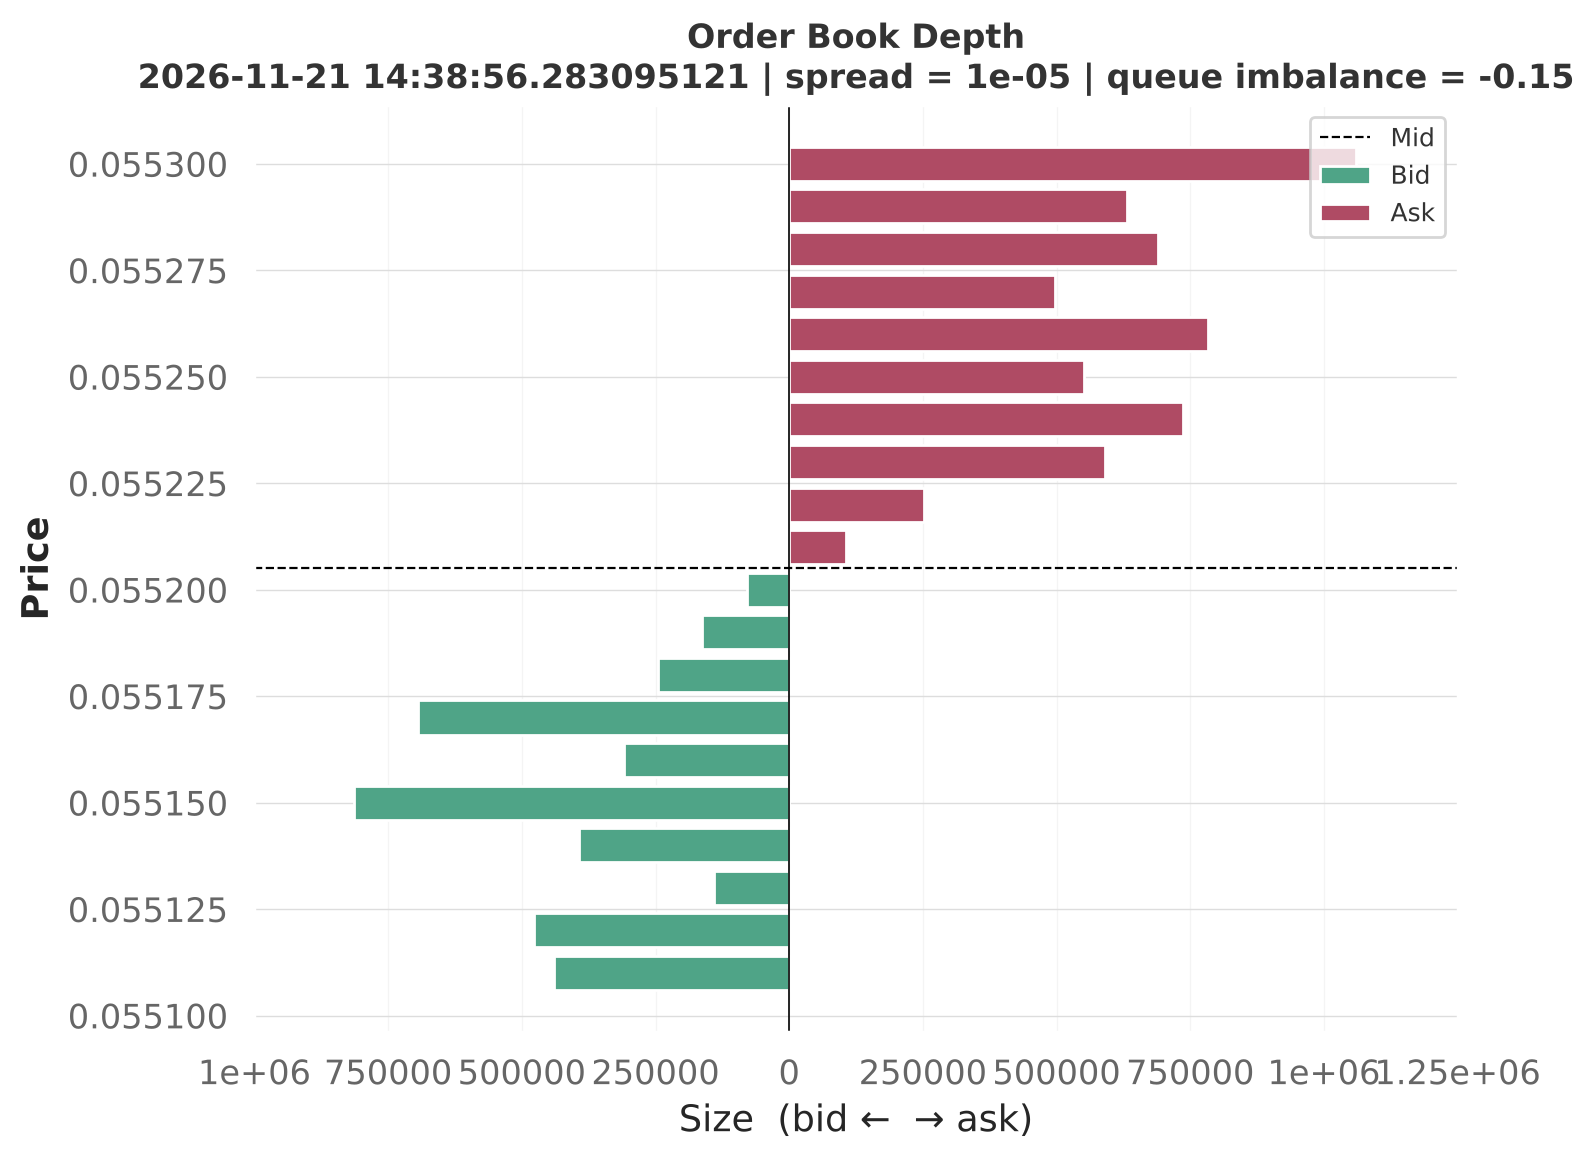

In [4]:
qs.plots.lob_depth(book)

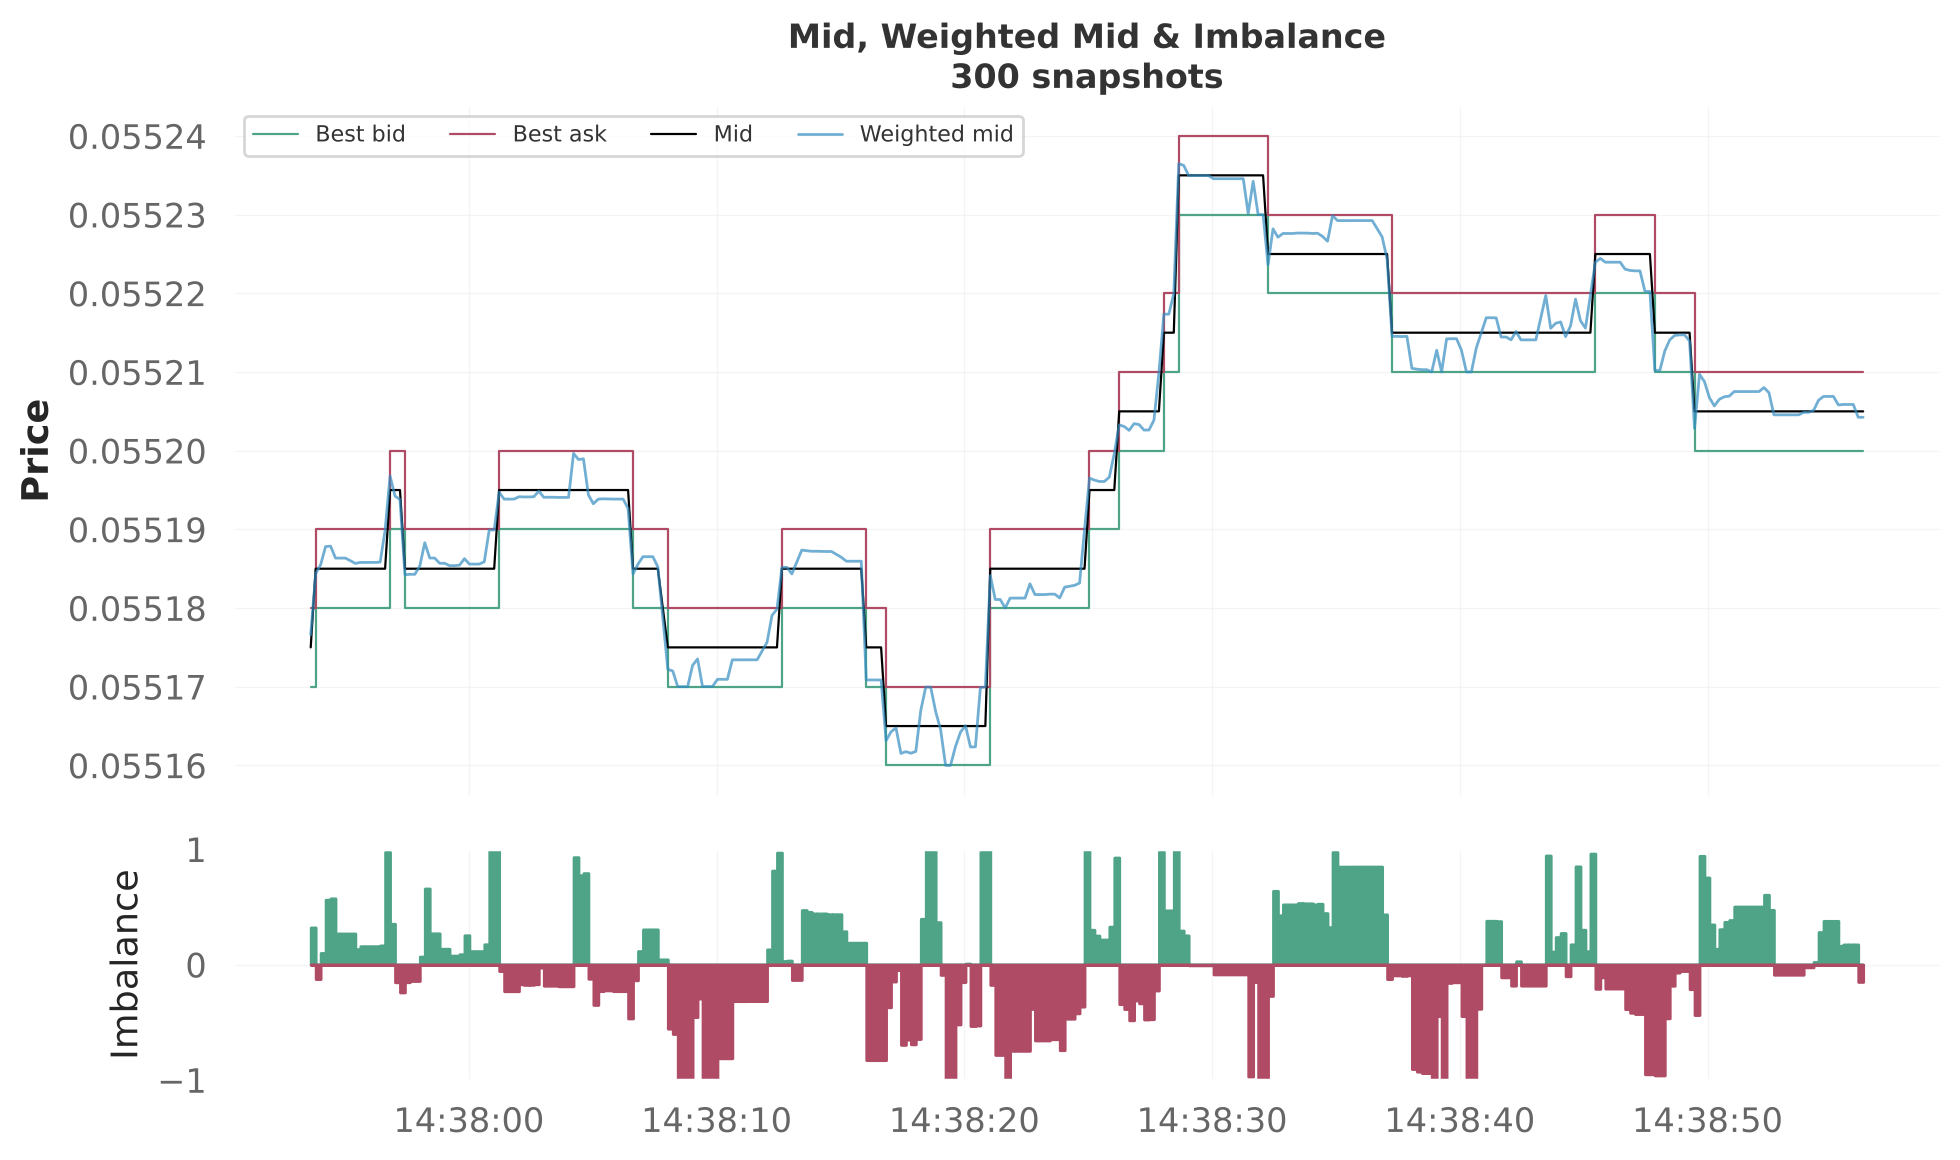

In [5]:
qs.plots.lob_timeseries(book.iloc[-300:])

## 3. Does imbalance predict the next move?

For each imbalance bucket, how often is the **next** mid-price change up or down?
A useful signal shows P(up) rising steadily from left to right.

In [6]:
signal = lob.imbalance_signal(book, bins=5)
signal.assign(mean_move_ticks=signal["mean_move"] / tick).drop(columns="mean_move").round(3)

,count,p_up,p_down,p_flat,mean_imbalance,mean_move_ticks
imbalance,,,,,,
"(-1.001, -0.6]",228,0.355,0.645,0.0,-0.858,-0.219
"(-0.6, -0.2]",401,0.374,0.626,0.0,-0.379,-0.264
"(-0.2, 0.2]",406,0.534,0.466,0.0,-0.005,0.111
"(0.2, 0.6]",254,0.610,0.390,0.0,0.362,0.417
"(0.6, 1.0]",101,0.772,0.228,0.0,0.844,0.713


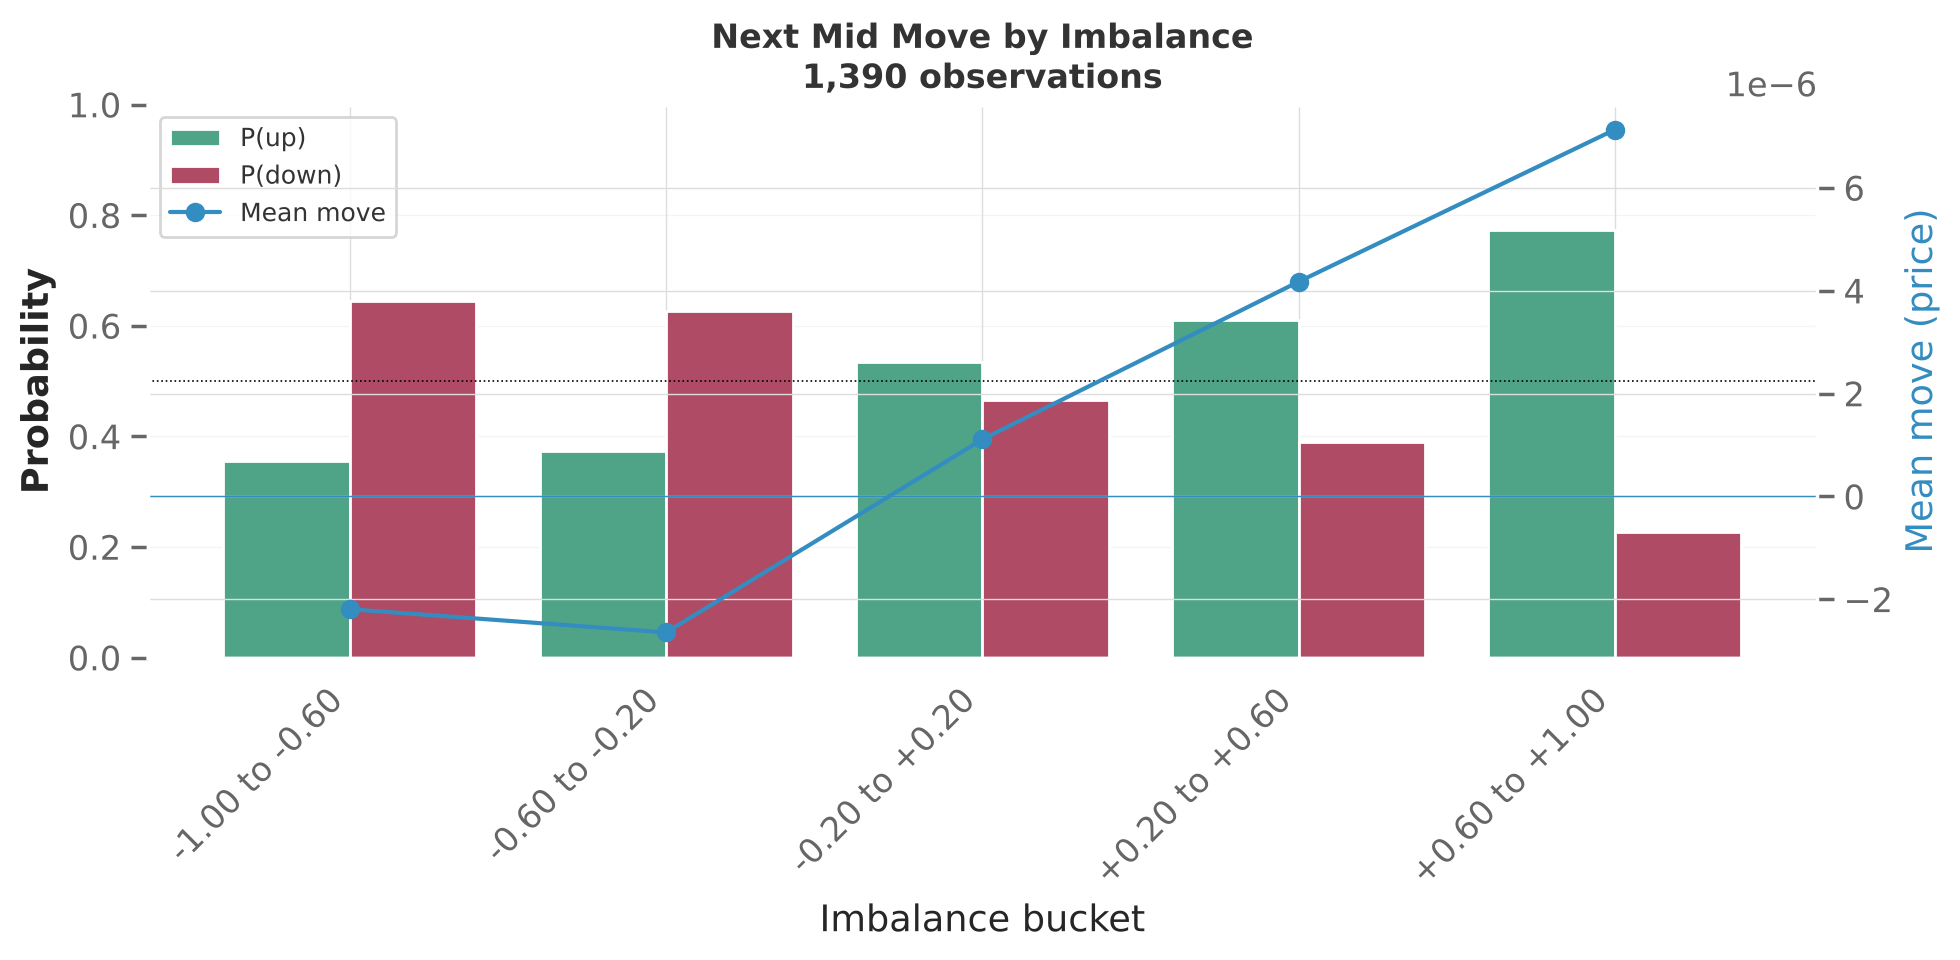

In [7]:
qs.plots.lob_imbalance_signal(signal)

## 4. Order flow imbalance and price impact

OFI nets out bid-side additions against ask-side additions (and the reverse for
cancellations and trades). Cont, Kukanov & Stoikov (2014) show mid changes over
short windows are close to linear in OFI.

In [8]:
impact = lob.price_impact(book, freq="10s")
impact_deep = lob.price_impact(book, freq="10s", levels=min(5, lob.levels(book)), normalize_depth=True)
iofi = lob.integrated_ofi(book, freq="10s", levels=min(5, lob.levels(book)))
print(f"best level: beta={impact.beta:.3g}, t={impact.beta_tstat:.1f}, R2={impact.r2:.2f}, n={impact.nobs}")
print(f"5 levels, depth-normalised: R2={impact_deep.r2:.2f}")
print("integrated OFI level weights:", iofi.weights.round(3).to_dict())

best level: beta=3.02e-11, t=8.6, R2=0.72, n=31
5 levels, depth-normalised: R2=0.83
integrated OFI level weights: {'ofi_1': 0.09, 'ofi_2': 0.177, 'ofi_3': 0.223, 'ofi_4': 0.256, 'ofi_5': 0.253}


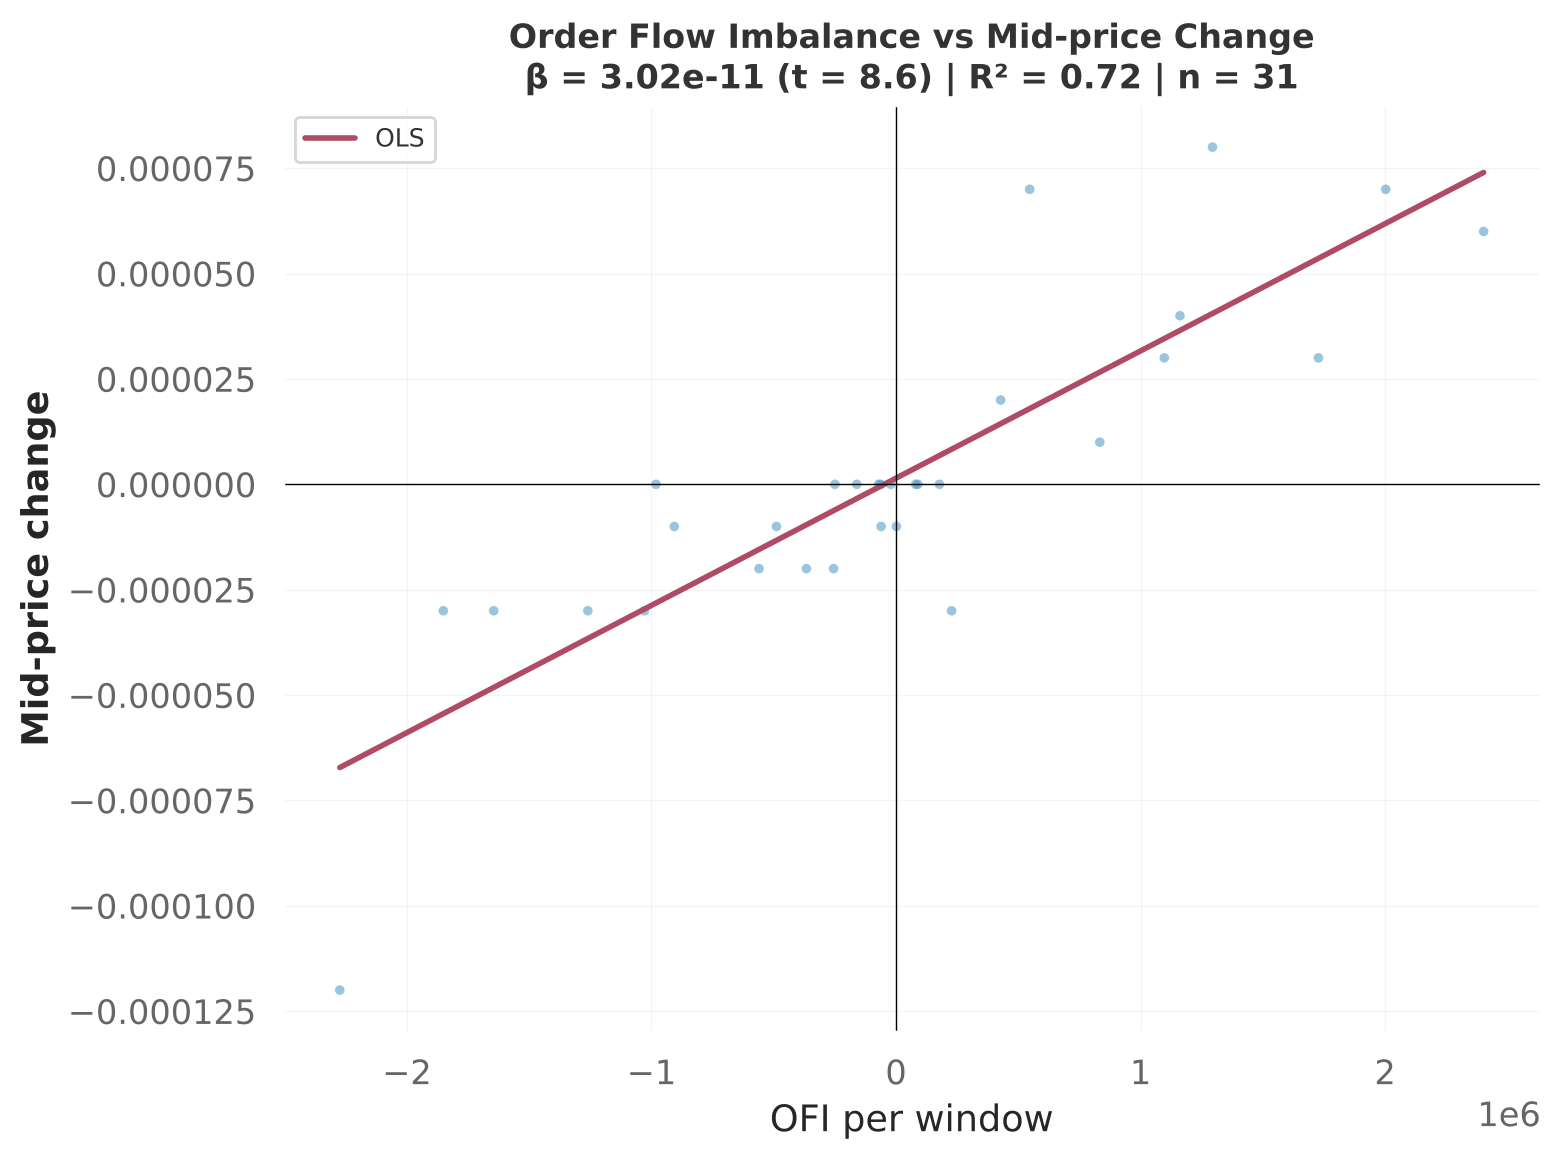

In [9]:
qs.plots.lob_price_impact(impact)

## 5. Micro-price, tested out of sample

Fit Stoikov's micro-price on the first half of the recording, then check on the
second half which price best predicts the **next different mid**: the mid, the
size-weighted mid, or the micro-price.

In [10]:
half = len(book) // 2
train, test = book.iloc[:half], book.iloc[half:]
model = lob.fit_microprice(train, tick_size=tick, n_imbalance=6, n_spread=2)
(model.adjustment / tick).round(3)

spread_ticks,1,2
imbalance,,
"[0.0, 0.16666666666666666)",-0.734,NaN
"[0.16666666666666666, 0.3333333333333333)",-0.370,NaN
"[0.3333333333333333, 0.5)",-0.105,NaN
"[0.5, 0.6666666666666666)",0.105,NaN
"[0.6666666666666666, 0.8333333333333333)",0.370,NaN
"[0.8333333333333333, 1.0)",0.734,NaN


In [11]:
mid = lob.mid_price(test)
changed = mid.diff().fillna(1) != 0
run = changed.cumsum().to_numpy() - 1
target = pd.Series(mid[changed].shift(-1).to_numpy()[run], index=mid.index)
ok = target.notna()

def mse(pred):
    return float((((target - pred)[ok]) / tick).pow(2).mean())

scores = pd.Series({
    "mid": mse(mid),
    "weighted mid": mse(lob.weighted_mid(test)),
    "micro-price (long run, g*)": mse(model.predict(test)),
    "micro-price (next move, g1)": mse(model.predict(test, first_order=True)),
}, name="out-of-sample MSE (ticks^2)")
scores.to_frame().assign(vs_mid_pct=lambda d: (100 * (1 - d.iloc[:, 0] / scores["mid"])).round(1)).round(4)

,out-of-sample MSE (ticks^2),vs_mid_pct
mid,1.2121,0.0
weighted mid,1.2101,0.2
"micro-price (long run, g*)",1.2890,-6.3
"micro-price (next move, g1)",1.2576,-3.8


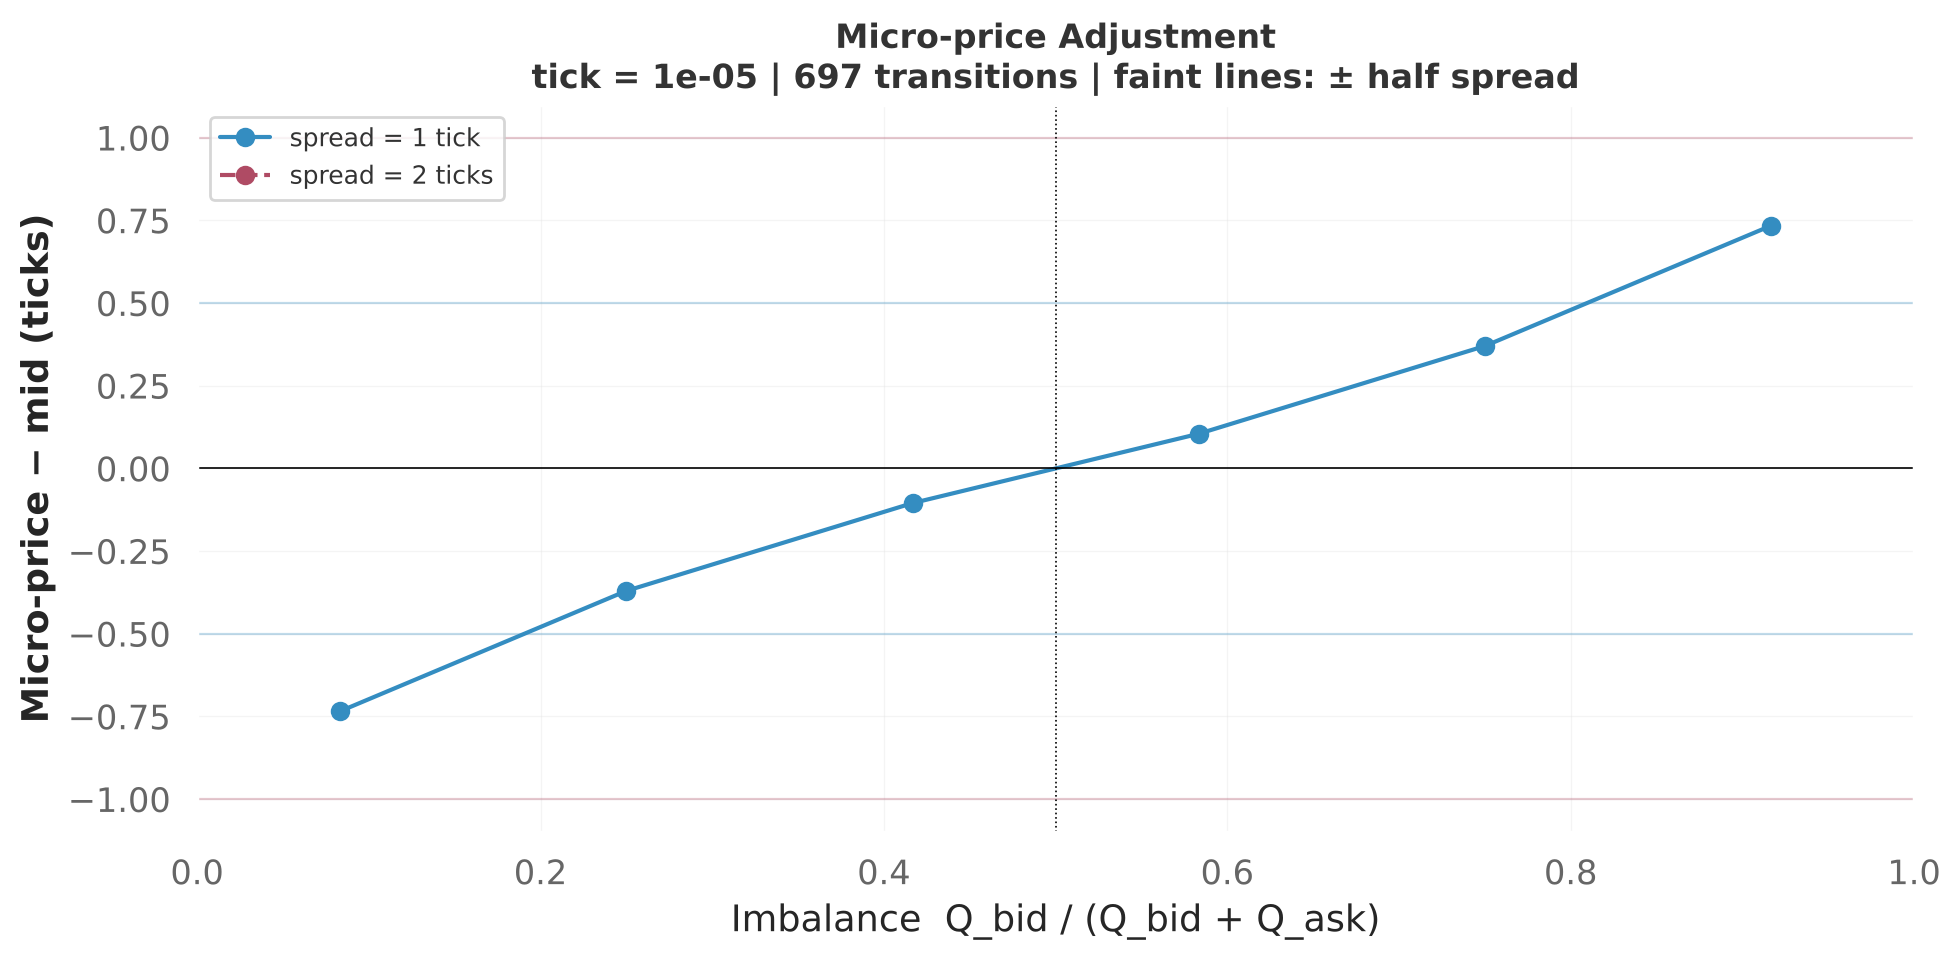

In [12]:
qs.plots.lob_microprice(model)

## Reading the results

What we found running these models on 20–25 minutes of live Binance books
(BTC, ETH, DOGE, XRP, TRX), fitting on the first half and testing on the second:

* **Imbalance** predicted the direction of the next move on every symbol: P(up)
  rose from 0.24–0.37 in the most negative bucket to 0.63–0.79 in the most
  positive.
* **OFI** explained 53–58% of 10-second mid changes at the best level, and
  60–80% using five levels normalised by depth (highest on large-tick coins).
* The **micro-price** only helps on large-tick books, where the spread is one
  tick. There it cut the error of the mid by 2–22% out of sample, but the
  plain size-weighted mid did about as well, and a market that trends between
  the training and test halves can make the micro-price worse than the mid
  (the model is symmetric by construction). On BTC and ETH it adds nothing:
  the mid jumps many ticks between snapshots.
* A few minutes of data is noisy; rerun with a longer `SECONDS` before trusting
  any single number.

References: Cont, Kukanov & Stoikov (2014), *The price impact of order book
events*; Cont, Cucuringu & Zhang (2023), *Cross-impact of order flow imbalance*;
Gould & Bonart (2016), *Queue imbalance as a one-tick-ahead price predictor*;
Stoikov (2018), *The micro-price*.